# CMP 가상 계측 고도화 (v2)

`ML_CMP Project.ipynb`(v1)의 다음 단계입니다. v1 결론은 아래와 같았습니다.

- 연마 구간(`STAGE_ROTATION > 0`) 평균 + 공정 그룹 + 랜덤 포레스트 → test RMSE **5.454** (그룹 평균 기준선 7.181)
- 사용량 카운터는 미래 예측에서 해가 되어 제외, 미래 CV(TimeSeriesSplit) **5.789**
- 45일 학습 → 20일 순차 예측에서 EWMA 편향 보정, 5장 중 1장 실측으로 6.153 → 5.316

v2에서 확인하는 질문은 네 가지입니다.

| 단계 | 질문 | 수업 연결 |
|---|---|---|
| C1 | 연마 구간을 **평균 하나**가 아니라 레시피 스텝·흔들림(표준편차)까지 요약하면 나아지는가? | ML4 피처 공학 |
| C2 | 랜덤 포레스트 말고 다른 앙상블(Extra Trees, 그레이디언트 부스팅), 그룹별 모델은? | ML7·ML9 앙상블 |
| C3 | 불순도 중요도 1위였던 리테이너 링 압력은 **미래 예측에서도** 중요한가? (순열 중요도) | ML4 특성 중요도 |
| C5 | EWMA 보정은 **더 강한 기준선**(실측만으로 만든 EWMA)보다도 좋은가? 측정이 늦게 오면? | 공정제어 EWMA |
| C6 | 모델이 낡아 가는 것을 언제 알아챌 수 있는가? (잔차 EWMA 관리도) | 공정제어 · SPC |

데이터는 v1과 같은 `PHM-Data-Challenge/` 폴더를 씁니다. 첫 셀이 폴더가 없으면(Colab 등) GitHub에서 자동으로 받습니다.

In [1]:
# [C0-0단계] 실행 환경 맞추기 — 맥(ML25 폴더)이면 그대로, Colab이면 데이터 받기 + 한글 폰트 설치
import os, sys, platform, subprocess
if not os.path.exists("PHM-Data-Challenge"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/akangel0307/PHM-Data-Challenge.git"], check=True)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts(fontpaths=["/usr/share/fonts/truetype/nanum"]):
        fm.fontManager.addfont(f)
KOREAN_FONT = "AppleGothic" if platform.system() == "Darwin" else ("NanumGothic" if IN_COLAB else "AppleGothic")
print("환경:", "Colab" if IN_COLAB else platform.system(), "| 한글 폰트:", KOREAN_FONT, "| 데이터 폴더:", os.path.exists("PHM-Data-Challenge"))

환경: Linux | 한글 폰트: AppleGothic | 데이터 폴더: True


In [2]:
# [C0단계] 준비 — v1에서 만든 함수 그대로 + 스텝 피처 함수 추가 ⏳ 데이터 읽기 약 1분
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

plt.rcParams["font.family"] = KOREAN_FONT        # 맥: AppleGothic, Colab: NanumGothic
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

base = "PHM-Data-Challenge/data/2016 PHM Data Challenge/"

def load_set(folder, label_file):
    # 시계열을 합치고(빈 파일 제외), 정답에 챔버 번호를 붙여서 돌려줌
    files = sorted(glob.glob(base + folder + "*.csv"))
    frames = []
    for f in files:
        d = pd.read_csv(f)
        if len(d) > 0:
            frames.append(d)
    ts = pd.concat(frames, ignore_index=True)
    y = pd.read_csv(base + label_file)
    chamber = ts.groupby(["WAFER_ID", "STAGE"])["CHAMBER"].min().reset_index()
    return ts, y.merge(chamber, on=["WAFER_ID", "STAGE"])

D = "2016 PHM DATA CHALLENGE CMP DATA SET/"
V = "2016 PHM DATA CHALLENGE CMP VALIDATION DATA SET/"
train_ts, train_y = load_set(D + "CMP-data/training/", D + "CMP-training-removalrate.csv")
valid_ts, valid_y = load_set(V + "validation/", V + "CMP-validation-removalrate.csv")
test_ts,  test_y  = load_set(D + "CMP-data/test/", D + "CMP-test-removalrate.csv")

# v1 2-3단계: training 안에서만 정한 이상치 기준
a1 = train_y[(train_y["STAGE"] == "A") & (train_y["CHAMBER"] == 1)]
q1, q3 = a1["AVG_REMOVAL_RATE"].quantile([0.25, 0.75])
upper = q3 + 3 * (q3 - q1)
train_y_clean = train_y.drop(a1[a1["AVG_REMOVAL_RATE"] > upper].index)
print("train:", train_ts.shape, train_y_clean.shape, "| valid:", valid_y.shape, "| test:", test_y.shape)

train: (672744, 25) (1977, 4) | valid: (424, 4) | test: (424, 4)


In [3]:
# [C0-2단계] 웨이퍼 단위 표 — v1 make_table / add_features + 새 피처
process = ["PRESSURIZED_CHAMBER_PRESSURE", "MAIN_OUTER_AIR_BAG_PRESSURE", "CENTER_AIR_BAG_PRESSURE",
           "RETAINER_RING_PRESSURE", "RIPPLE_AIR_BAG_PRESSURE", "EDGE_AIR_BAG_PRESSURE",
           "WAFER_ROTATION", "STAGE_ROTATION", "HEAD_ROTATION",
           "SLURRY_FLOW_LINE_A", "SLURRY_FLOW_LINE_B", "SLURRY_FLOW_LINE_C"]
pressures = process[:6]
usage = ["USAGE_OF_BACKING_FILM", "USAGE_OF_DRESSER", "USAGE_OF_POLISHING_TABLE",
         "USAGE_OF_DRESSER_TABLE", "USAGE_OF_MEMBRANE", "USAGE_OF_PRESSURIZED_SHEET"]
key = ["WAFER_ID", "STAGE"]

def make_table(ts, y):
    y = y.copy()
    y["GROUP"] = y["STAGE"] + "_" + y["CHAMBER"].astype(int).astype(str)
    polishing = ts[ts["STAGE_ROTATION"] > 0]
    active = polishing.groupby(key)[process].mean().reset_index()
    polish_time = polishing.groupby(key).size().reset_index(name="POLISH_TIME")
    active = active.merge(polish_time, on=key)
    table = y.merge(active, on=key, how="left")
    table["NO_POLISH"] = table["POLISH_TIME"].isna().astype(int)
    table[process + ["POLISH_TIME"]] = table[process + ["POLISH_TIME"]].fillna(0)
    return table

def add_features(table, ts):
    wear = ts.groupby(key)[usage].mean().reset_index()
    start = ts.groupby(key)["TIMESTAMP"].min().reset_index(name="START_TIME")
    return table.merge(wear, on=key).merge(start, on=key)

def add_step_features(table, ts):
    # [새 피처] 연마 구간을 '평균 하나' 대신 레시피 스텝과 흔들림으로 요약 (FDC 방식)
    polishing = ts[ts["STAGE_ROTATION"] > 0].copy()
    polishing["STEP"] = pd.cut(polishing["STAGE_ROTATION"], [0, 30, 100, 165, 230, 400],
                               labels=["ramp", "s66", "s131", "s197", "s263"])
    # (1) 스텝별 머문 시간(초)
    step_time = polishing.groupby(key + ["STEP"], observed=False).size().unstack(fill_value=0)
    step_time.columns = ["T_" + c for c in step_time.columns]
    # (2) 연마 구간 안에서 압력·슬러리가 얼마나 흔들렸는지(표준편차)
    sd = polishing.groupby(key)[pressures + ["SLURRY_FLOW_LINE_C"]].std().add_prefix("SD_")
    # (3) 마지막 고속 스텝(263 rpm)의 평균 압력
    main = polishing[polishing["STEP"] == "s263"].groupby(key)[pressures].mean().add_prefix("M_")
    new = pd.concat([step_time, sd, main], axis=1).reset_index()
    return table.merge(new, on=key, how="left")

def build(ts, y):
    return add_step_features(add_features(make_table(ts, y), ts), ts)

train_table = build(train_ts, train_y_clean)
valid_table = build(valid_ts, valid_y)
test_table  = build(test_ts, test_y)

# 시간순 정렬 + 경과일 (v1 5-3단계와 같은 기준)
t0 = train_table["START_TIME"].min()
for t in (train_table, valid_table, test_table):
    t["DAY"] = (t["START_TIME"] - t0) / 86400
train_table = train_table.sort_values("START_TIME").reset_index(drop=True)

step_cols = [c for c in train_table.columns if c.startswith("T_")]
sd_cols   = [c for c in train_table.columns if c.startswith("SD_")]
main_cols = [c for c in train_table.columns if c.startswith("M_")]
print("표 크기:", train_table.shape, valid_table.shape, test_table.shape)
print("새 피처:", step_cols + sd_cols + main_cols)

표 크기: (1977, 45) (424, 45) (424, 45)
새 피처: ['T_ramp', 'T_s66', 'T_s131', 'T_s197', 'T_s263', 'SD_PRESSURIZED_CHAMBER_PRESSURE', 'SD_MAIN_OUTER_AIR_BAG_PRESSURE', 'SD_CENTER_AIR_BAG_PRESSURE', 'SD_RETAINER_RING_PRESSURE', 'SD_RIPPLE_AIR_BAG_PRESSURE', 'SD_EDGE_AIR_BAG_PRESSURE', 'SD_SLURRY_FLOW_LINE_C', 'M_PRESSURIZED_CHAMBER_PRESSURE', 'M_MAIN_OUTER_AIR_BAG_PRESSURE', 'M_CENTER_AIR_BAG_PRESSURE', 'M_RETAINER_RING_PRESSURE', 'M_RIPPLE_AIR_BAG_PRESSURE', 'M_EDGE_AIR_BAG_PRESSURE']


## C1. FDC 스텝 요약 피처

v1은 연마 구간을 평균 하나로 요약했습니다. 그런데 레시피는 플래튼 회전을 66 → 131 → 197 rpm으로 올린 뒤 잠깐 멈추고 263 rpm으로 마무리하는 **스텝 구조**입니다. 현업 FDC(이상 감지)는 센서를 레시피 스텝별로 요약하므로, 같은 방식으로 세 종류 피처를 추가했습니다.

- `T_*` : 스텝별 머문 시간(초)
- `SD_*` : 연마 구간 안에서 압력·슬러리 유량의 표준편차 (스텝이 바뀔 때 압력이 얼마나 출렁였는가)
- `M_*` : 마지막 고속 스텝(263 rpm)의 평균 압력

평가는 v1에서 정한 대로 **미래 예측(TimeSeriesSplit 5)** 을 기준으로 합니다.

       T_ramp  T_s66  T_s131  T_s197  T_s263
GROUP                                       
A_1       3.0   14.0    13.0    15.0    22.0
A_4       4.0   21.0    23.0    23.0    42.0
B_4       4.0   21.0    24.0    23.0    42.0


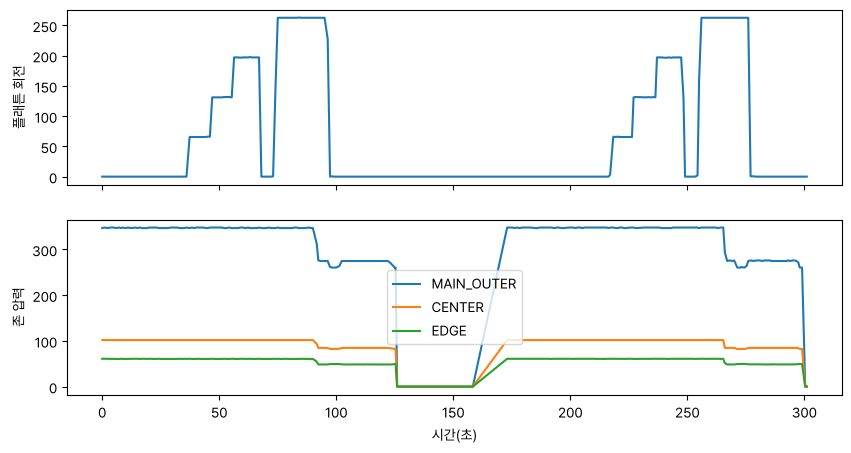

In [4]:
# [C1-1단계] 레시피 스텝 구조 확인 — 그룹별 스텝 시간(초) 중앙값
has_log = train_table["NO_POLISH"] == 0
print(train_table[has_log].groupby("GROUP")[step_cols].median())

one = train_ts[(train_ts["WAFER_ID"] == train_ts["WAFER_ID"].iloc[0]) & (train_ts["STAGE"] == "A")]
t = one["TIMESTAMP"] - one["TIMESTAMP"].min()
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, one["STAGE_ROTATION"]); ax[0].set_ylabel("플래튼 회전")
for c in ["MAIN_OUTER_AIR_BAG_PRESSURE", "CENTER_AIR_BAG_PRESSURE", "EDGE_AIR_BAG_PRESSURE"]:
    ax[1].plot(t, one[c], label=c.replace("_AIR_BAG_PRESSURE", ""))
ax[1].set_ylabel("존 압력"); ax[1].set_xlabel("시간(초)"); ax[1].legend()
plt.show()

In [5]:
# [C1-2단계] 피처 묶음 비교 — 미래 예측 기준 ⏳ 약 1분
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

cat_attribs = ["GROUP"]
def make_preprocessing(num_attribs):
    num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    cat_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),
                                 OneHotEncoder(handle_unknown="ignore"))
    return ColumnTransformer([("num", num_pipeline, num_attribs),
                              ("cat", cat_pipeline, cat_attribs)])

def forest(cols):
    return make_pipeline(make_preprocessing(cols), RandomForestRegressor(random_state=42, n_jobs=-1))

X_sorted = train_table.drop("AVG_REMOVAL_RATE", axis=1)
y_sorted = train_table["AVG_REMOVAL_RATE"].copy()
X_valid = valid_table.drop("AVG_REMOVAL_RATE", axis=1)
y_valid = valid_table["AVG_REMOVAL_RATE"].copy()
tscv = TimeSeriesSplit(n_splits=5)

v1_features = process + ["POLISH_TIME", "NO_POLISH"]          # v1 최종 피처
feature_sets = {
    "v1 (연마 구간 평균)":   v1_features,
    "v1 + 스텝 시간":        v1_features + step_cols,
    "v1 + 고속 스텝 압력":   v1_features + main_cols,
    "v1 + 흔들림(SD)":       v1_features + sd_cols,
    "v1 + 전부":             v1_features + step_cols + main_cols + sd_cols,
}
rows = []
for name, cols in feature_sets.items():
    scores = -cross_val_score(forest(cols), X_sorted, y_sorted, cv=tscv,
                              scoring="neg_root_mean_squared_error")
    valid_rmse = root_mean_squared_error(y_valid, forest(cols).fit(X_sorted, y_sorted).predict(X_valid))
    rows.append({"피처 묶음": name, "피처 수": len(cols) + 3, "미래 CV": scores.mean(),
                 "fold별": np.round(scores, 2), "valid": valid_rmse})
c1_result = pd.DataFrame(rows).set_index("피처 묶음")
c1_result.round(3)

,피처 수,미래 CV,fold별,valid
피처 묶음,,,,
v1 (연마 구간 평균),17,5.789,"[5.44, 6.08, 5.67, 6.72, 5.03]",5.556
v1 + 스텝 시간,22,5.837,"[5.59, 6.22, 5.64, 6.77, 4.97]",5.529
v1 + 고속 스텝 압력,23,5.791,"[5.41, 6.23, 5.83, 6.47, 5.02]",5.541
v1 + 흔들림(SD),24,5.695,"[5.24, 6.04, 5.71, 6.48, 5.0]",5.476
v1 + 전부,35,5.758,"[5.3, 6.23, 5.69, 6.5, 5.07]",5.439


**C1 해석.** 표준편차(SD) 피처를 더한 묶음이 미래 CV를 가장 많이 낮췄고, 스텝 시간은 오히려 나빠졌습니다. 레시피가 스텝 시간을 거의 고정하고 있어(그룹별 중앙값이 거의 같음) 스텝 시간은 정보가 적고, 대신 **스텝이 바뀌는 동안 압력이 얼마나 출렁였는가**가 웨이퍼 간 차이를 조금 더 설명합니다. 개선 폭은 작습니다(5.789 → 5.695, 약 1.6%). 이후 단계는 `v1 + 흔들림(SD)`를 v2 피처로 씁니다.

In [6]:
# [C2단계] 다른 앙상블 · 그룹별 모델 비교 (ML7·ML9) ⏳ 약 1분
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin, clone

v2_features = v1_features + sd_cols

class PerGroupModel(BaseEstimator, RegressorMixin):
    # 공정 그룹마다 따로 학습하는 모델 (A_1 / A_4 / B_4)
    def __init__(self, model):
        self.model = model
    def fit(self, X, y):
        self.models_ = {g: clone(self.model).fit(X[X["GROUP"] == g], y[X["GROUP"] == g])
                        for g in X["GROUP"].unique()}
        return self
    def predict(self, X):
        pred = np.zeros(len(X))
        for g, m in self.models_.items():
            mask = (X["GROUP"] == g).values
            if mask.any():
                pred[mask] = m.predict(X[mask])
        return pred

candidates = {
    "랜덤 포레스트":        forest(v2_features),
    "엑스트라 트리":        make_pipeline(make_preprocessing(v2_features), ExtraTreesRegressor(random_state=42, n_jobs=-1)),
    "그레이디언트 부스팅":   make_pipeline(make_preprocessing(v2_features), HistGradientBoostingRegressor(random_state=42)),
    "그룹별 랜덤 포레스트":  PerGroupModel(forest(v2_features)),
}
rows = []
for name, model in candidates.items():
    scores = -cross_val_score(model, X_sorted, y_sorted, cv=tscv, scoring="neg_root_mean_squared_error")
    valid_rmse = root_mean_squared_error(y_valid, clone(model).fit(X_sorted, y_sorted).predict(X_valid))
    rows.append({"모델": name, "미래 CV": scores.mean(), "fold별": np.round(scores, 2), "valid": valid_rmse})
c2_result = pd.DataFrame(rows).set_index("모델")
c2_result.round(3)

,미래 CV,fold별,valid
모델,,,
랜덤 포레스트,5.695,"[5.24, 6.04, 5.71, 6.48, 5.0]",5.476
엑스트라 트리,5.711,"[5.4, 6.04, 5.56, 6.43, 5.12]",5.576
그레이디언트 부스팅,5.875,"[5.52, 6.11, 5.83, 6.75, 5.18]",5.429
그룹별 랜덤 포레스트,5.673,"[5.32, 6.0, 5.57, 6.48, 4.99]",5.402


**C2 해석.** 네 모델의 미래 CV 차이는 0.2 이내였습니다. 그룹별 랜덤 포레스트가 5.673으로 가장 낮았지만 단일 모델(5.695)과 0.02 차이라 fold 간 흔들림(±0.5)보다 훨씬 작고, 그레이디언트 부스팅은 미래 구간에서 오히려 나빴습니다(학습 범위 밖 드리프트에 더 민감). 그래서 관리할 모델이 하나인 **단일 랜덤 포레스트를 v2 모델로 유지**합니다. 모델 종류보다 **무엇을 피처로 쓰고 어떻게 평가하느냐**가 결과를 더 많이 움직인다는 v1의 결론이 다시 확인됩니다.

## C3. 미래 예측에서도 중요한가 — 순열 중요도

v1의 특성 중요도(불순도 기반)는 **학습 데이터**에서 트리가 얼마나 자주·효과적으로 나눴는지를 잽니다. 미래 예측에 실제로 기여하는지는 **순열 중요도**로 확인합니다: TimeSeriesSplit 각 fold의 **시험(미래) 구간**에서 피처를 섞었을 때 RMSE가 얼마나 나빠지는지 봅니다.

압력 평균과 압력 SD처럼 서로 상관된 피처는 하나만 섞으면 다른 피처가 정보를 대신해 중요도가 과소평가되므로, **같은 계열을 한꺼번에 섞는 그룹 순열 중요도**를 씁니다.

In [7]:
# [C3단계] 불순도 중요도 vs 미래 구간 그룹 순열 중요도 ⏳ 약 1분
families = {
    "압력 평균":     pressures,
    "압력 흔들림(SD)": [c for c in sd_cols if "SLURRY" not in c],
    "회전":          ["WAFER_ROTATION", "STAGE_ROTATION", "HEAD_ROTATION"],
    "슬러리 유량":    ["SLURRY_FLOW_LINE_A", "SLURRY_FLOW_LINE_B", "SLURRY_FLOW_LINE_C", "SD_SLURRY_FLOW_LINE_C"],
    "연마 시간":      ["POLISH_TIME", "NO_POLISH"],
}
rng = np.random.default_rng(42)
perm_rows, impurity_rows = [], []
for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_sorted), start=1):
    model = forest(v2_features).fit(X_sorted.iloc[tr_idx], y_sorted.iloc[tr_idx])
    X_te, y_te = X_sorted.iloc[te_idx], y_sorted.iloc[te_idx]
    base_rmse = root_mean_squared_error(y_te, model.predict(X_te))
    row = {"fold": fold}
    for fam, cols in families.items():
        worse = []
        for r in range(5):
            X_perm = X_te.copy()
            X_perm[cols] = X_te[cols].values[rng.permutation(len(X_te))]   # 계열 전체를 같은 순서로 섞음
            worse.append(root_mean_squared_error(y_te, model.predict(X_perm)) - base_rmse)
        row[fam] = np.mean(worse)
    perm_rows.append(row)
    # 같은 모델의 불순도 중요도(센서만, 계열별 합)
    imp = pd.Series(model[-1].feature_importances_, index=model[0].get_feature_names_out())
    imp = imp[imp.index.str.startswith("num__")]; imp.index = imp.index.str.replace("num__", "")
    impurity_rows.append({fam: imp[cols].sum() / imp.sum() for fam, cols in families.items()})

perm = pd.DataFrame(perm_rows).set_index("fold")
impurity = pd.DataFrame(impurity_rows).mean()
c3_result = pd.DataFrame({"불순도 중요도(센서 중 비율)": impurity,
                          "순열 중요도(미래 RMSE 증가)": perm.mean()}).round(3)
print(perm.round(2))
c3_result

      압력 평균  압력 흔들림(SD)    회전  슬러리 유량  연마 시간
fold                                        
1      0.34        0.74 -0.01    0.15   0.05
2      0.53        1.82  0.11    0.85   0.26
3      0.09        1.12 -0.01    0.02   0.04
4      0.12        0.61 -0.04    0.15   0.04
5     -0.21        1.07 -0.04    0.07   0.05


,불순도 중요도(센서 중 비율),순열 중요도(미래 RMSE 증가)
압력 평균,0.239,0.173
압력 흔들림(SD),0.446,1.071
회전,0.104,0.003
슬러리 유량,0.170,0.246
연마 시간,0.041,0.090


단일 피처 순열 중요도 하위 5개(음수 = 섞었더니 오히려 좋아짐):
RETAINER_RING_PRESSURE    -0.111
STAGE_ROTATION            -0.064
EDGE_AIR_BAG_PRESSURE     -0.061
CENTER_AIR_BAG_PRESSURE   -0.052
HEAD_ROTATION             -0.026
dtype: float64


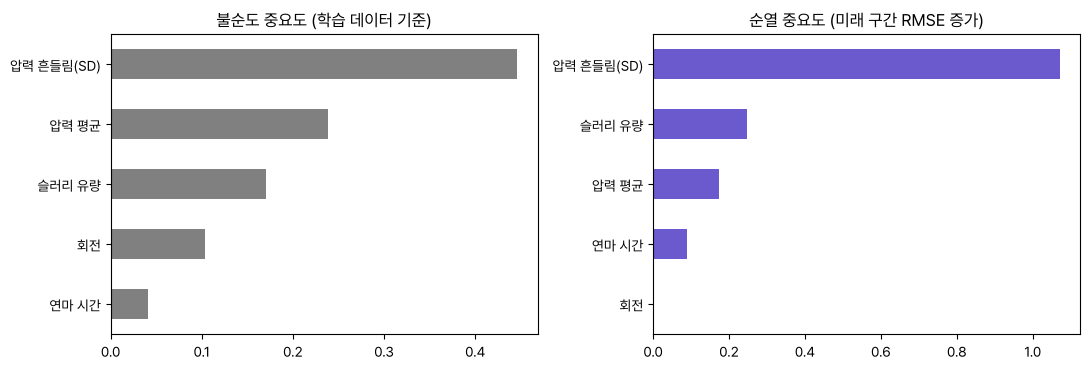

In [8]:
# [C3-2단계] 그림으로 비교
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
c3_result.iloc[:, 0].sort_values().plot.barh(ax=ax[0], color="gray")
ax[0].set_title("불순도 중요도 (학습 데이터 기준)")
c3_result.iloc[:, 1].sort_values().plot.barh(ax=ax[1], color="slateblue")
ax[1].set_title("순열 중요도 (미래 구간 RMSE 증가)")
plt.tight_layout(); plt.show()

# 단일 피처 순열 중요도로 보면 어떻게 되나 — 마지막 fold
from sklearn.inspection import permutation_importance
tr_idx, te_idx = list(tscv.split(X_sorted))[-1]
model = forest(v2_features).fit(X_sorted.iloc[tr_idx], y_sorted.iloc[tr_idx])
single = permutation_importance(model, X_sorted.iloc[te_idx][v2_features + ["GROUP"]], y_sorted.iloc[te_idx],
                                n_repeats=10, random_state=42, scoring="neg_root_mean_squared_error", n_jobs=-1)
single = pd.Series(single.importances_mean, index=v2_features + ["GROUP"]).drop("GROUP").sort_values()
print("단일 피처 순열 중요도 하위 5개(음수 = 섞었더니 오히려 좋아짐):")
print(single.head(5).round(3))

**C3 해석.** 미래 구간에서 가장 중요한 계열은 **압력의 흔들림(SD)** 이었고, 회전 계열은 거의 0이었습니다(레시피상 V 고정, v1과 일치). 반면 v1에서 불순도 중요도 1위였던 **리테이너 링 압력 평균**은 단일 피처로 섞었을 때 오히려 미래 오차가 약간 줄었습니다. 압력 설정값이 기간에 따라 조금씩 바뀌어(v1 3-6단계, 압력–경과일 상관 −0.26) 일부는 '그 무렵'을 알려주는 시간 대리 변수처럼 작동했다는 뜻입니다. **불순도 중요도만으로 "리테이너 링이 MRR을 좌우한다"고 말하면 안 된다**는 것이 C3의 교훈입니다.

In [9]:
# [C4단계] v2 최종 모델 — 봉인한 test로 한 번만 평가 (v1과 같은 조건에서 나란히) ⏳ 약 30초
from scipy import stats

X_test = test_table.drop("AVG_REMOVAL_RATE", axis=1)
y_test = test_table["AVG_REMOVAL_RATE"].copy()
grp_mean = train_table.groupby("GROUP")["AVG_REMOVAL_RATE"].mean()

def report(name, y_true, y_pred, groups):
    out = {"모델": name, "RMSE": root_mean_squared_error(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred)}
    for g in ["A_1", "A_4", "B_4"]:
        m = (groups == g).values
        out[g] = root_mean_squared_error(y_true[m], y_pred[m])
    return out

v1_model = forest(v1_features).fit(X_sorted, y_sorted)
v2_model = forest(v2_features).fit(X_sorted, y_sorted)
pred_v1, pred_v2 = v1_model.predict(X_test), v2_model.predict(X_test)
c4_result = pd.DataFrame([
    report("기준선: 그룹 평균", y_test, X_test["GROUP"].map(grp_mean).values, X_test["GROUP"]),
    report("v1 랜덤 포레스트", y_test, pred_v1, X_test["GROUP"]),
    report("v2 랜덤 포레스트 (+SD)", y_test, pred_v2, X_test["GROUP"]),
]).set_index("모델")

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))
ci = stats.bootstrap((y_test.values, pred_v2), rmse, paired=True, vectorized=False,
                     confidence_level=0.95, random_state=42).confidence_interval
print(f"v2 test RMSE 95% 신뢰구간: {ci.low:.3f} ~ {ci.high:.3f}")
c4_result.round(3)

v2 test RMSE 95% 신뢰구간: 4.939 ~ 5.775


,RMSE,MAE,A_1,A_4,B_4
모델,,,,,
기준선: 그룹 평균,7.181,5.550,3.924,6.478,8.619
v1 랜덤 포레스트,5.454,4.197,4.224,5.421,5.893
v2 랜덤 포레스트 (+SD),5.326,4.075,4.171,5.341,5.704


## C5. R2R 고도화 — 더 강한 기준선, 측정 지연, 하이브리드

v1 B단계는 "VM 예측만" 대비 EWMA 보정의 효과를 보았습니다. 그런데 현업에서 진짜 경쟁 상대는 **센서 없이 최근 실측값만 EWMA로 이어 쓰는 방법**입니다. MRR은 연속한 웨이퍼끼리 매우 비슷하기 때문입니다(아래 자기상관). 그래서 네 가지 전략을 같은 조건에서 비교합니다.

| 전략 | 웨이퍼 n의 예측 |
|---|---|
| VM만 | ŷ(센서) |
| 실측만 EWMA | 그룹 평균 + b,  b ← λ(y − 그룹 평균) + (1 − λ)b |
| VM + EWMA (v1 B단계) | ŷ + b,  b ← λ(y − ŷ) + (1 − λ)b |
| 하이브리드 | 그룹 평균 + α(ŷ − 그룹 평균) + b — VM이 말하는 '평소와 다른 정도'를 α만큼만 믿음 |

조건은 두 가지를 바꿉니다: **샘플링 간격**(몇 장마다 1장 측정)과 **측정 지연**(측정 결과가 몇 장 뒤에 도착하는가). λ와 α는 **45~55일에서 고르고 55~65일에서 평가**해, v1에서 한계로 적었던 '같은 기간에서 고르고 평가'하는 낙관 편향을 없앴습니다.

In [10]:
# [C5-1단계] 45일까지로 학습 → 45~65일을 한 장씩 순서대로
past   = train_table[train_table["DAY"] < 45]
future = train_table[train_table["DAY"] >= 45].reset_index(drop=True)
vm_model = forest(v2_features).fit(past.drop("AVG_REMOVAL_RATE", axis=1), past["AVG_REMOVAL_RATE"])

vm_pred  = vm_model.predict(future.drop("AVG_REMOVAL_RATE", axis=1))
grp_avg  = future["GROUP"].map(past.groupby("GROUP")["AVG_REMOVAL_RATE"].mean()).values
actual   = future["AVG_REMOVAL_RATE"].values
groups   = future["GROUP"].values
tune = (future["DAY"] < 55).values          # λ·α를 고르는 기간
evaluate = ~tune                             # 평가 기간
print("미래 표본:", len(future), "| 고르기:", tune.sum(), "| 평가:", evaluate.sum(),
      "| 하루 평균 표본 수:", round(len(future) / 20, 1))

# 연속한 웨이퍼끼리 MRR이 얼마나 비슷한가 (그룹 안 자기상관)
for g in ["A_1", "A_4", "B_4"]:
    s = train_table.loc[train_table["GROUP"] == g, "AVG_REMOVAL_RATE"].values
    print(f"{g}: 바로 다음 표본과 r = {np.corrcoef(s[:-1], s[1:])[0, 1]:.2f}, 10개 뒤 r = {np.corrcoef(s[:-10], s[10:])[0, 1]:.2f}")

미래 표본: 628 | 고르기: 361 | 평가: 267 | 하루 평균 표본 수: 31.4
A_1: 바로 다음 표본과 r = 0.67, 10개 뒤 r = 0.33
A_4: 바로 다음 표본과 r = 0.86, 10개 뒤 r = 0.60
B_4: 바로 다음 표본과 r = 0.89, 10개 뒤 r = 0.67


In [11]:
# [C5-2단계] 측정 지연까지 넣은 EWMA 시뮬레이터
def ewma_run(base_pred, actual, groups, lam, every, delay):
    # base_pred: 보정 전 예측 / every장마다 1장 측정 / 측정 결과는 delay장 뒤에 도착
    bias, arriving, out = {}, [], np.zeros(len(base_pred))
    for i in range(len(base_pred)):
        while arriving and arriving[0][0] <= i:              # 도착한 측정만 편향에 반영
            _, g, err = arriving.pop(0)
            bias[g] = lam * err + (1 - lam) * bias.get(g, 0.0)
        out[i] = base_pred[i] + bias.get(groups[i], 0.0)     # 먼저 예측을 내고
        if i % every == 0:                                   # 이 웨이퍼를 측정하면, 결과는 나중에 도착
            arriving.append((i + 1 + delay, groups[i], actual[i] - base_pred[i]))
    return out

def strategy_pred(name, alpha=1.0):
    if name == "VM만":        return vm_pred
    if name == "실측만 EWMA":  return grp_avg
    if name == "VM + EWMA":   return vm_pred
    if name == "하이브리드":   return grp_avg + alpha * (vm_pred - grp_avg)

def tune_and_evaluate(name, every, delay):
    # 45~55일에서 λ(와 α)를 고르고, 55~65일 RMSE를 돌려줌
    if name == "VM만":
        return root_mean_squared_error(actual[evaluate], vm_pred[evaluate]), None, None
    alphas = [0.25, 0.5, 0.75] if name == "하이브리드" else [1.0]
    best = None
    for a in alphas:
        for lam in [0.1, 0.2, 0.3, 0.5]:
            p = ewma_run(strategy_pred(name, a), actual, groups, lam, every, delay)
            score = root_mean_squared_error(actual[tune], p[tune])
            if best is None or score < best[0]:
                best = (score, lam, a, p)
    _, lam, a, p = best
    return root_mean_squared_error(actual[evaluate], p[evaluate]), lam, a

print("예: 5장마다 측정, 지연 0 →", round(tune_and_evaluate("VM + EWMA", 5, 0)[0], 3))

예: 5장마다 측정, 지연 0 → 5.079


In [12]:
# [C5-3단계] 샘플링 간격 × 측정 지연 — 어떤 전략이 이기나 ⏳ 약 30초
scenarios = [(1, 0), (5, 0), (5, 25), (5, 50), (25, 25), (25, 50), (25, 100)]
strategies = ["VM만", "실측만 EWMA", "VM + EWMA", "하이브리드"]
rows = []
for every, delay in scenarios:
    row = {"측정": f"{every}장마다 1장", "지연(장)": delay}
    for s in strategies:
        score, lam, a = tune_and_evaluate(s, every, delay)
        row[s] = score
        if s == "하이브리드":
            row["α, λ"] = f"{a}, {lam}"
    rows.append(row)
c5_result = pd.DataFrame(rows)
c5_result["가장 좋은 전략"] = c5_result[strategies].idxmin(axis=1)
c5_result.round(3)

,측정,지연(장),VM만,실측만 EWMA,VM + EWMA,하이브리드,"α, λ",가장 좋은 전략
0,1장마다 1장,0,5.456,3.726,4.886,3.724,"0.25, 0.5",하이브리드
1,5장마다 1장,0,5.456,4.152,5.079,4.055,"0.25, 0.5",하이브리드
2,5장마다 1장,25,5.456,4.936,5.356,4.613,"0.5, 0.3",하이브리드
3,5장마다 1장,50,5.456,5.194,5.109,4.685,"0.5, 0.2",하이브리드
4,25장마다 1장,25,5.456,5.534,5.210,5.011,"0.25, 0.5",하이브리드
5,25장마다 1장,50,5.456,5.697,5.229,4.803,"0.75, 0.2",하이브리드
6,25장마다 1장,100,5.456,6.147,5.219,5.105,"0.75, 0.5",하이브리드


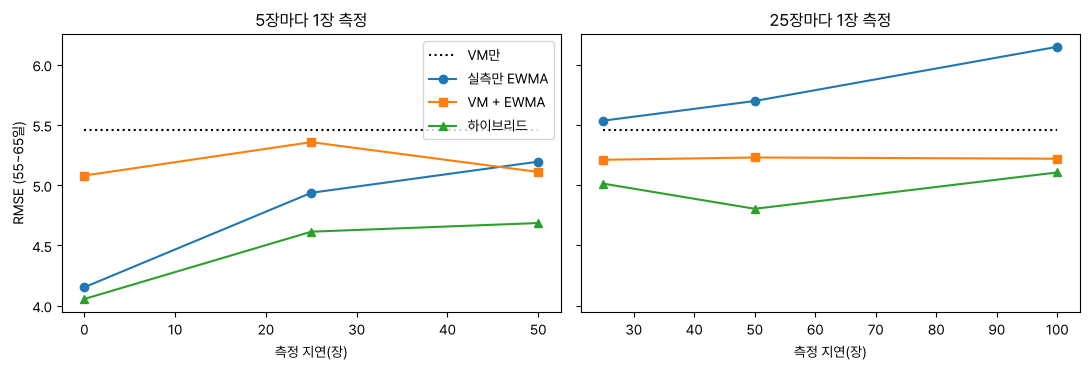

In [13]:
# [C5-4단계] 그림 — 지연이 길어질수록 VM의 가치가 커진다
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for k, every in enumerate([5, 25]):
    part = c5_result[c5_result["측정"] == f"{every}장마다 1장"]
    for s, style in zip(strategies, ["k:", "o-", "s-", "^-"]):
        ax[k].plot(part["지연(장)"], part[s], style, label=s)
    ax[k].set_title(f"{every}장마다 1장 측정"); ax[k].set_xlabel("측정 지연(장)")
ax[0].set_ylabel("RMSE (55~65일)"); ax[0].legend()
plt.tight_layout(); plt.show()

In [14]:
# [C5-5단계] 연마 시간 제어로 환산 — 두께가 목표에서 몇 % 벗어나나
# 정지층 없는 연마: 연마 시간 = 목표 제거량 / 예측 MRR → 실제 제거량 / 목표 = 실제 MRR / 예측 MRR
every, delay = 25, 50          # 로트(25장)당 1장 측정, 결과는 약 1.5일 뒤 (하루 약 31표본 기준)
plans = {"고정 시간(그룹 평균 MRR)": grp_avg}
for s in ["VM만", "실측만 EWMA", "VM + EWMA", "하이브리드"]:
    _, lam, a = tune_and_evaluate(s, every, delay)
    plans[s] = vm_pred if s == "VM만" else ewma_run(strategy_pred(s, a), actual, groups, lam, every, delay)

rows = []
for name, p in plans.items():
    err = (actual / p - 1) * 100              # 목표 대비 실제 제거량 오차(%)
    row = {"연마 시간 결정 방식": name}
    for g in ["A_4", "B_4"]:
        m = evaluate & (groups == g)
        row[f"{g} 두께 오차 σ(%)"] = err[m].std()
        row[f"{g} 평균 치우침(%)"] = err[m].mean()
        row[f"{g} 총 오차 RMS(%)"] = np.sqrt(np.mean(err[m] ** 2))
    rows.append(row)
c5_thickness = pd.DataFrame(rows).set_index("연마 시간 결정 방식")
c5_thickness.round(2)

,A_4 두께 오차 σ(%),A_4 평균 치우침(%),A_4 총 오차 RMS(%),B_4 두께 오차 σ(%),B_4 평균 치우침(%),B_4 총 오차 RMS(%)
연마 시간 결정 방식,,,,,,
고정 시간(그룹 평균 MRR),5.48,4.09,6.84,6.73,11.12,13.00
VM만,6.21,1.62,6.42,7.24,4.30,8.42
실측만 EWMA,5.35,-1.47,5.55,8.32,1.23,8.41
VM + EWMA,6.20,1.32,6.34,7.16,3.22,7.85
하이브리드,5.55,0.92,5.62,6.47,2.56,6.96


## C6. 모델이 낡는 것을 알아채기 — 잔차 EWMA 관리도

VM 모델은 시간이 지나면 드리프트 때문에 낡습니다. 측정되는 웨이퍼의 **잔차(실측 − VM 예측)** 에 EWMA 관리도를 걸면, 잔차가 한쪽으로 쌓이는 시점을 잡을 수 있습니다. 20일까지로 학습한 모델을 20~65일에 그대로 쓰면서 5장마다 1장 측정한다고 가정했습니다. 관리 한계는 학습 기간 OOB(out-of-bag) 잔차의 표준편차 σ로 ±L·σ·√(λ / (2 − λ)), λ = 0.2, L = 3입니다.

σ = 5.82, 관리 한계 = ±5.82, 측정 116장 중 경보 65장, 첫 경보: 33.2일
드레서 교체: [ 6.  26.9 46. ] 일


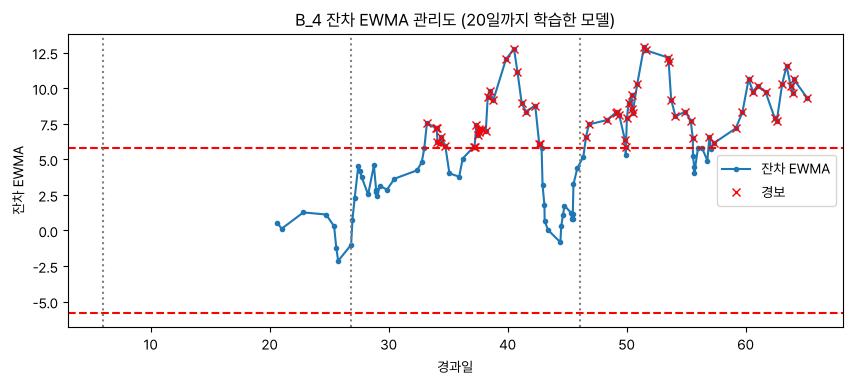

In [15]:
# [C6단계] 잔차 EWMA 관리도 (B_4)
ref = train_table[train_table["DAY"] < 20]
mon = train_table[train_table["DAY"] >= 20].copy()
rf_oob = RandomForestRegressor(random_state=42, n_jobs=-1, oob_score=True)
monitor_model = make_pipeline(make_preprocessing(v2_features), rf_oob).fit(ref, ref["AVG_REMOVAL_RATE"])
ref_resid = ref["AVG_REMOVAL_RATE"].values - rf_oob.oob_prediction_
mon["RESID"] = mon["AVG_REMOVAL_RATE"].values - monitor_model.predict(mon)

lam, L, g = 0.2, 3, "B_4"
sigma = ref_resid[ref["GROUP"].values == g].std()
limit = L * sigma * np.sqrt(lam / (2 - lam))
sampled = mon[mon["GROUP"] == g].iloc[::5].copy()
z, zs = 0.0, []
for r in sampled["RESID"]:
    z = lam * r + (1 - lam) * z
    zs.append(z)
sampled["EWMA"] = zs
alarm = sampled[np.abs(sampled["EWMA"]) > limit]
print(f"σ = {sigma:.2f}, 관리 한계 = ±{limit:.2f}, 측정 {len(sampled)}장 중 경보 {len(alarm)}장, 첫 경보: {alarm['DAY'].min():.1f}일")

# 드레서 교체 시점(USAGE_OF_DRESSER가 크게 떨어지는 날)
b4 = train_table[train_table["GROUP"] == g]
drop = b4["USAGE_OF_DRESSER"].diff() < -0.5 * b4["USAGE_OF_DRESSER"].max()
replace_days = b4.loc[drop, "DAY"].values
print("드레서 교체:", np.round(replace_days, 1), "일")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(sampled["DAY"], sampled["EWMA"], "o-", markersize=3, label="잔차 EWMA")
ax.axhline(limit, color="red", ls="--"); ax.axhline(-limit, color="red", ls="--")
ax.plot(alarm["DAY"], alarm["EWMA"], "rx", label="경보")
for d in replace_days:
    ax.axvline(d, color="gray", ls=":")
ax.set_xlabel("경과일"); ax.set_ylabel("잔차 EWMA"); ax.legend(); ax.set_title("B_4 잔차 EWMA 관리도 (20일까지 학습한 모델)")
plt.show()

## 정리 — v2에서 바뀐 것과 새로 알게 된 것

| 단계 | 결과 | 의미 |
|---|---|---|
| C1 피처 | 압력 흔들림(SD) 추가로 미래 CV 5.789 → 5.695 | 레시피 스텝이 바뀔 때의 압력 출렁임이 웨이퍼 차이를 조금 더 설명 |
| C2 모델 | 부스팅·엑스트라 트리·그룹별 모델 모두 ±0.2 이내 | 모델 종류보다 피처와 평가 설계가 중요 |
| C3 해석 | 미래 구간 1위 계열은 **압력 흔들림**, 회전은 ≈ 0. 리테이너 링 **평균**은 단일 순열 중요도 음수 | v1의 "리테이너 링 1위"는 불순도 중요도의 착시 일부. 설정값 변화가 시간 대리 변수로 작동 |
| C4 test | v1 5.454 → v2 **5.326** (95% CI 4.94 ~ 5.78), 기준선 대비 −26% | test는 v1 이후 두 번째 사용. v2는 미래 CV만으로 고른 뒤 열었음 |
| C5 R2R | 모든 조건에서 **하이브리드(그룹 평균 + α·VM 편차 + EWMA)** 가 1위 | 측정이 빨리 오면 실측 EWMA만으로도 거의 충분, 늦을수록 VM이 필요 |
| C5 두께 | 로트당 1장 측정·1.5일 지연에서 B_4 두께 총 오차 RMS 13.0% → 7.0% (고정 시간 대비) | VM의 가치는 측정 지연·샘플링 정책과 함께 평가해야 함 |
| C6 감시 | 20일까지 학습한 모델이 33일부터 관리 한계 이탈 | 잔차 EWMA 관리도를 재학습 시점 신호로 사용 가능 |

**가장 큰 교훈.** v1의 B단계는 "VM만" 대비 EWMA의 효과를 보았지만, 더 강한 기준선(센서 없이 실측만 EWMA)과 비교하면 측정이 바로 들어오는 조건에서는 VM + EWMA가 오히려 졌습니다(4.89 vs 3.73). MRR은 연속한 웨이퍼끼리 상관이 0.86 ~ 0.89로 매우 높아 최근 실측값이 가장 좋은 예측이기 때문입니다. VM은 **측정이 드물거나 늦게 오는 구간을 메우는 도구**이고, 둘을 섞은 하이브리드가 모든 조건에서 가장 안정적이었습니다.